## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Abdullah Rana

**Date:** October 15, 2026 - I used one of my grace days as I was super busy and couldn't make the original deadline. 

# Q1. Noise and $k$-Means Clustering


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

### Q1.1 - Create the datasets


In [35]:
def createData(noise, N=50):
    np.random.seed(100) # Set the seed for replicability
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])

    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}
print(pd.DataFrame({noise: df['group'].value_counts() for noise, df in datasets.items()}))


       0.125  0.250  0.500  1.000  2.000
group                                   
a         50     50     50     50     50
b         50     50     50     50     50
c         50     50     50     50     50


The prompt says four datasets, but the supplied code creates five. I use all five, with 150 points each and 50 points per group. The group centers stay at (1, 1), (3, 2), and (5, 3), and only the standard deviation changes. Resetting the seed inside the function also means each dataset uses the same underlying random draws, scaled by the noise level.

### Q1.2 - Scatterplots by group


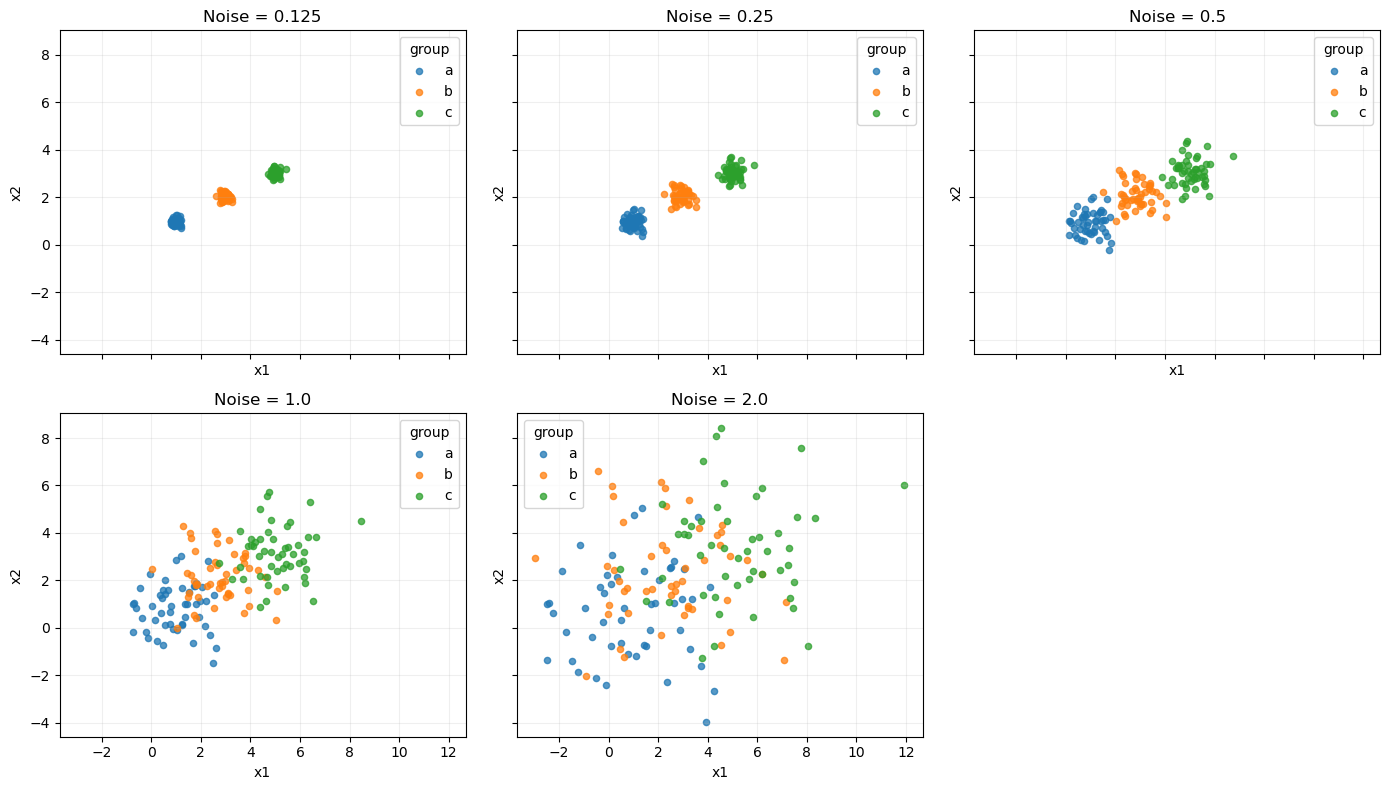

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)

for ax, (noise, df) in zip(axes.flat, datasets.items()):
    for group in ['a', 'b', 'c']:
        sub = df[df['group'] == group]
        ax.scatter(sub['x1'], sub['x2'], s=20, alpha=0.75, label=group)
    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend(title='group')
    ax.grid(alpha=0.2)

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()


At 0.125 and 0.25, the groups form three tight clouds with clear gaps between them. At 0.5, the clouds spread toward each other, but the three groups are still mostly distinct. At 1.0, there is substantial overlap, especially between neighboring groups. At 2.0, the colors are mixed together and it is hard to identify three separate clusters by eye.

The centers have not moved. What changes is the spread around each center relative to the distance between centers. Once that spread is large enough, a point generated by group a can be closer to the center of group b than to its own group's center.

### Q1.3 - Scree plots and choosing $k$


     0.125   0.250   0.500   1.000    2.000
k                                          
1   511.61  533.25  606.62  873.69  1889.20
2   128.89  142.72  186.78  361.59  1071.81
3     4.91   19.65   77.78  254.88   790.48
4     4.33   17.33   67.19  210.15   591.18
5     3.76   15.08   58.67  174.92   498.19
6     3.26   12.89   50.32  147.21   418.79
7     2.79   11.17   43.05  123.19   356.70
8     2.45    9.70   36.63  105.92   303.69
9     2.11    8.24   32.66   93.56   264.42
10    1.88    7.47   29.67   82.42   237.28


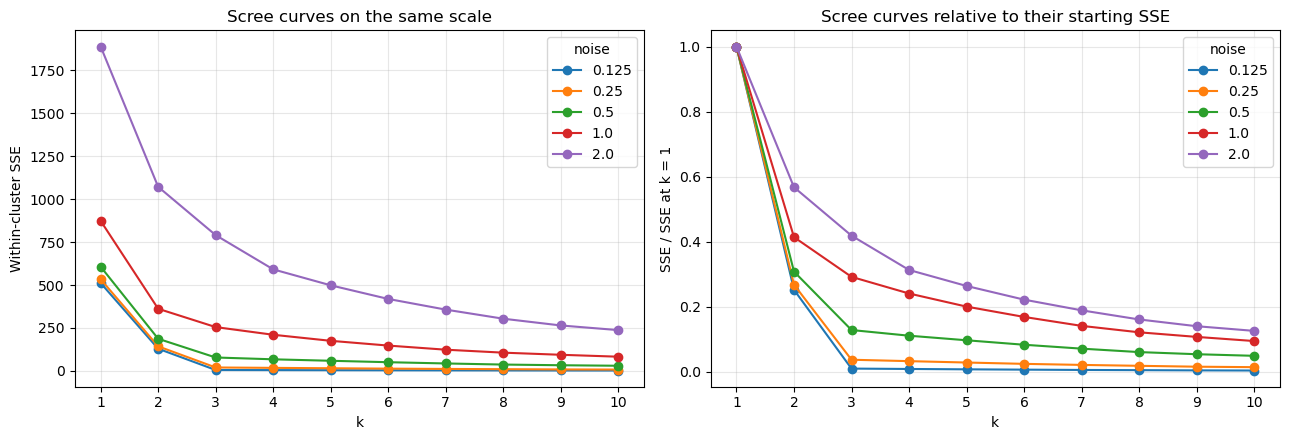

In [37]:
k_grid = range(1, 11)
sse_noise = pd.DataFrame(index=list(k_grid))

for noise, df in datasets.items():
    sse = []
    for k in k_grid:
        model = KMeans(n_clusters=k, random_state=100, n_init=20)
        model.fit(df[['x1', 'x2']])
        sse.append(model.inertia_)
    sse_noise[noise] = sse

sse_noise.index.name = 'k'
print(sse_noise.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for noise in datasets:
    axes[0].plot(sse_noise.index, sse_noise[noise], marker='o', label=noise)
    axes[1].plot(sse_noise.index, sse_noise[noise] / sse_noise.loc[1, noise],
                 marker='o', label=noise)

axes[0].set_ylabel('Within-cluster SSE')
axes[0].set_title('Scree curves on the same scale')
axes[1].set_ylabel('SSE / SSE at k = 1')
axes[1].set_title('Scree curves relative to their starting SSE')
for ax in axes:
    ax.set_xlabel('k')
    ax.set_xticks(list(k_grid))
    ax.legend(title='noise')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


With noise 0.125, SSE falls from 511.61 at $k=1$ to 128.89 at $k=2$ and 4.91 at $k=3$, then only to 4.33 at $k=4$. That is a clear elbow at 3. The same pattern holds at 0.25, and 0.5 still has a reasonably clear elbow at 3, although the remaining SSE is higher.

At noise 1.0, SSE is 873.69, 361.59, 254.88, and 210.15 for $k=1,2,3,4$. Most of the improvement happens going from 1 to 2, and there is no equally sharp stopping point at 3. At noise 2.0, the curve bends gradually rather than showing three obvious groups. A choice around 2 or 3 could be defended from those noisier curves, but I would not say the elbow definitively identifies the true number of generating groups.

The common vertical scale shows that more noise leaves much more error even with three centers. The relative plot makes it easier to compare curve shape without the largest-noise dataset dominating the graph. I fit the models using only `x1` and `x2`; `group` is used for the scatterplot, not as a clustering feature.


### Q1.4 - Intuition of the elbow


$k$-means minimizes the sum of squared distances from observations to their assigned centers:

$$\mathrm{SSE} = \sum_{j=1}^{k}\sum_{i\in C_j}\lVert x_i-\mu_j\rVert^2.$$

With one center, the model has to represent all three clouds with a single point. Adding a second center removes a lot of the distance between groups, and adding a third lets each tight cloud have its own center. Once that structure has been captured, extra centers mostly split up the random variation inside the clouds, so each additional center helps much less. That change from large improvements to small improvements creates the elbow.

When the clouds overlap, there is less separation between capturing a new group and subdividing an existing one. Extra centers keep reducing error by dividing the same broad cloud, and the elbow gets harder to see. SSE alone cannot select $k$ by taking its minimum, since it generally falls as centers are added. We look for diminishing returns, and the result is a judgment rather than a guarantee that we recovered the original groups.


# Q2. Military Spending Clusters


### Q2.1 - Load and clean the 2020 data


In [38]:
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df2020 = df.loc[df['Year'] == 2020].copy()

print('all years:', df.shape)
print('2020 before dropping missing:', df2020.shape)
print(df2020.isna().sum())

df2020 = df2020.dropna().copy()
df2020 = df2020.drop(columns=['index']).reset_index(drop=True)
df2020['Country'] = df2020['Country'].str.strip()

features = ['Spending (2020 USD)', 'Spending per Capita',
            'Percent of Government Spending', 'Percent of GDP']

print('2020 complete cases:', df2020.shape)
print('duplicate countries:', df2020['Country'].duplicated().sum())
print('negative values:', (df2020[features] < 0).sum().sum())
print('infinite values:', np.isinf(df2020[features]).sum().sum())
print(df2020[features].dtypes)
print(df2020[features].describe().round(4))
df2020.head()


all years: (5882, 7)
2020 before dropping missing: (173, 7)
index                              0
Year                               0
Country                            0
Spending (2020 USD)               23
Percent of GDP                    23
Percent of Government Spending    25
Spending per Capita               24
dtype: int64
2020 complete cases: (148, 6)
duplicate countries: 0
negative values: 0
infinite values: 0
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  Percent of Government Spending  Percent of GDP
count             148.0000             148.0000                        148.0000        148.0000
mean            13153.7477             268.2645                          0.0615          0.0196
std             68005.2361             430.4349                          0.0462          0.0150
min        

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
1,2020,Albania,187.433234,0.012583,0.037952,65.126211
2,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
3,2020,Angola,993.594405,0.014442,0.074624,30.231680
4,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


Filtering to 2020 and dropping rows with missing values leaves 148 countries, matching the assignment. I remove the old index column because it is a row identifier, and exclude Country and Year from the clustering features. Spending (2020 USD) is measured in millions of constant 2020 U.S. dollars, while Spending per Capita is in dollars per person. Both percentage columns are stored as proportions, so 0.037 represents 3.7%.

Further data-quality checks are needed even though all four variables load as numeric. Dividing Percent of GDP by Percent of Government Spending gives implied total government spending as a share of GDP. Zimbabwe’s values imply government spending of only 0.29% of GDP, while Belarus’s imply 3.87%. Both are suspiciously low and suggest possible reporting, unit, or denominator inconsistencies. The file alone does not establish the cause, so I would flag these observations rather than assume a correction.

I retain both countries for this analysis because there is no verified replacement value and an unusual observation is not automatically an error. However, Belarus sets the maximum government-spending share at 30.30%, so a possible error there affects min-max normalization and cluster membership. These results should therefore be interpreted cautiously, with excluding the flagged countries as a useful sensitivity check. Finally, all four features need normalization before clustering because their units and ranges differ.

### Q2.2 - Total spending and spending per capita


     Spending (2020 USD)  Spending per Capita  Percent of Government Spending  Percent of GDP
min                  0.0                  0.0                             0.0             0.0
max                  1.0                  1.0                             1.0             1.0
    k     SSE
0   1  5.4114
1   2  2.4353
2   3  1.3218
3   4  0.6294
4   5  0.4131
5   6  0.3070
6   7  0.2116
7   8  0.1471
8   9  0.1038
9  10  0.0856


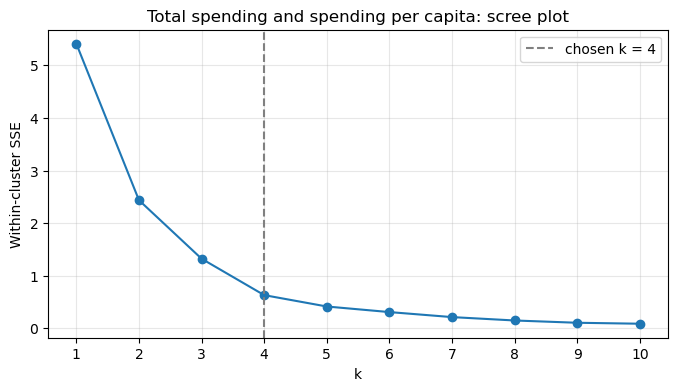

In [39]:
# Min-max normalization: keep the original units in df2020 for interpretation.
X_scaled = (df2020[features] - df2020[features].min()) / (
    df2020[features].max() - df2020[features].min())

print(X_scaled.agg(['min', 'max']).round(3))

spending_features = features[:2]
sse_spending = []
for k in k_grid:
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X_scaled[spending_features])
    sse_spending.append(model.inertia_)

print(pd.DataFrame({'k': list(k_grid), 'SSE': sse_spending}).round(4))
plt.figure(figsize=(8, 4))
plt.plot(list(k_grid), sse_spending, marker='o')
plt.axvline(4, linestyle='--', color='gray', label='chosen k = 4')
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('Total spending and spending per capita: scree plot')
plt.xticks(list(k_grid))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


I choose $k=4$. SSE drops from 5.4114 to 2.4353 to 1.3218 to 0.6294 for $k=1,2,3,4$, then the next improvement is much smaller, to 0.4131 at $k=5$. Three clusters would be a reasonable simpler alternative, but four captures another substantial improvement before the curve levels out. There is no unique mathematical optimum from an elbow plot; this is my choice based on diminishing returns.

I use `random_state=100` and 20 initializations for each fit so the comparison is reproducible and less dependent on one starting arrangement of centers. All models below use the same min-max scaling fitted on these 148 countries.


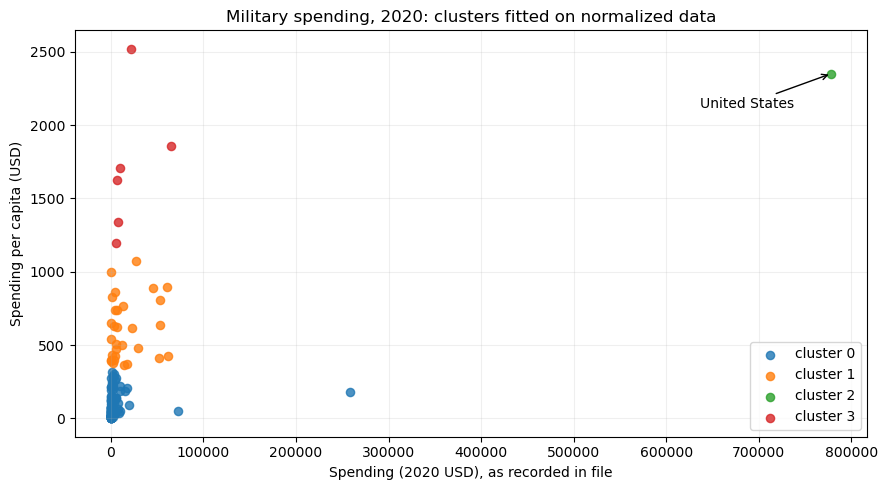

Spending (2020 USD)                                                                             Spending per Capita                                                              
                               count       mean       std        min        25%        50%        75%        max               count     mean     std      min      25%      50%      75%      max
cluster_spending                                                                                                                                                                                  
0                              111.0    4859.19  25405.74       8.62     130.01     382.46    2297.03  257973.43               111.0    80.06   83.50     0.58    14.88    47.06   125.39   314.20
1                               30.0   17077.59  20583.05     405.79    2294.04    5857.06   26296.00   61712.54                30.0   607.48  206.93   362.47   422.21   579.00   757.33  1070.62
2                                1.0  778397.20       NaN  778397.20  778397.20  778397.20  778397.20  778397.20                 1.0  2351.63     NaN  2351.63  2351.63  2351.63  2351.63  2351.63
3                                6.0   19443.36  22861.51    6095.71    7023.25    8624.23   18857.07   64558.40                 6.0  1706.72  466.38  1193.60  1412.08  1665.45  1817.22  2520.40

Countries in the smaller clusters:
1 : Australia, Austria, Bahrain, Belgium, Brunei, Canada, Cyprus, Denmark, Estonia, Finland, France, Germany, Greece, Italy, Japan, Korea, South, Latvia, Lithuania, Luxembourg, Netherlands, New Zealand, Poland, Portugal, Russia, Slovakia, Spain, Sweden, Switzerland, Taiwan, United Kingdom
2 : United States of America
3 : Israel, Kuwait, Norway, Oman, Saudi Arabia, Singapore
                 Country  cluster_spending
United States of America                 2


In [40]:
k_spending = 4
spending_model = KMeans(n_clusters=k_spending, random_state=100, n_init=20)
df2020['cluster_spending'] = spending_model.fit_predict(X_scaled[spending_features])

plt.figure(figsize=(9, 5))
for cluster in sorted(df2020['cluster_spending'].unique()):
    sub = df2020[df2020['cluster_spending'] == cluster]
    plt.scatter(sub['Spending (2020 USD)'], sub['Spending per Capita'],
                s=35, alpha=0.8, label=f'cluster {cluster}')
us = df2020[df2020['Country'] == 'United States of America']
plt.annotate('United States',
             (us['Spending (2020 USD)'].iloc[0], us['Spending per Capita'].iloc[0]),
             xytext=(-95, -25), textcoords='offset points',
             arrowprops={'arrowstyle': '->'})
plt.xlabel('Spending (2020 USD), as recorded in file')
plt.ylabel('Spending per capita (USD)')
plt.title('Military spending, 2020: clusters fitted on normalized data')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Describe in the original units, rather than normalized units.
display(df2020.groupby('cluster_spending')[spending_features].describe().round(2))
print('Countries in the smaller clusters:')
for cluster in [1, 2, 3]:
    print(cluster, ':', ', '.join(df2020.loc[df2020['cluster_spending'] == cluster, 'Country']))
print(us[['Country', 'cluster_spending']].to_string(index=False))


Cluster 0 contains 111 countries with average spending per capita of about $80. Cluster 1 contains 30 countries averaging about $607 per person, including many European countries, Australia, Canada, Japan, and South Korea. Cluster 3 contains six high-per-capita countries: Israel, Kuwait, Norway, Oman, Saudi Arabia, and Singapore. Their average is about $1,707 per person.

The United States is alone in cluster 2. Its total spending is 778,397.2 in the file's total-spending units, and spending per capita is about $2,352. Israel actually spends more per person, about $2,520, but the U.S. is far above everyone else in total spending. The singleton's standard deviation is NaN in the describe table because one observation has no sample standard deviation.

Most of the other separation follows spending per capita. China is in cluster 0 despite having the second-largest total budget, because its spending per person is only about $179. Min-max normalization gives both features the same range, but the U.S. maximum compresses most countries' normalized total spending near zero. A cluster with low per-capita spending therefore does not necessarily mean a small military budget. These groups describe spending profiles, not military effectiveness or alliances.


### Q2.3 - Government spending share and GDP share


    k     SSE
0   1  6.9609
1   2  2.9274
2   3  1.9958
3   4  1.4745
4   5  1.0728
5   6  0.8033
6   7  0.6462
7   8  0.5325
8   9  0.4450
9  10  0.3857


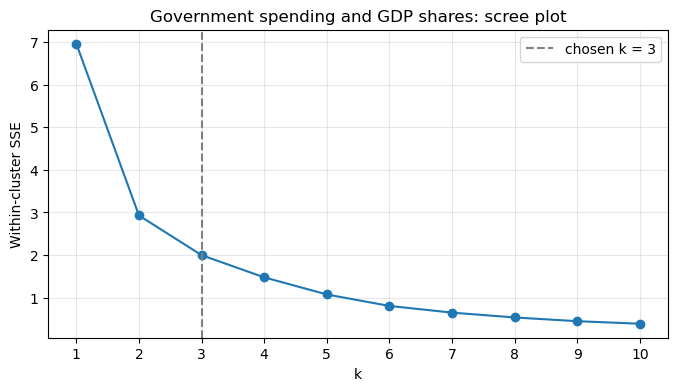

In [41]:
share_features = features[2:]
sse_shares = []
for k in k_grid:
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X_scaled[share_features])
    sse_shares.append(model.inertia_)

print(pd.DataFrame({'k': list(k_grid), 'SSE': sse_shares}).round(4))
plt.figure(figsize=(8, 4))
plt.plot(list(k_grid), sse_shares, marker='o')
plt.axvline(3, linestyle='--', color='gray', label='chosen k = 3')
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('Government spending and GDP shares: scree plot')
plt.xticks(list(k_grid))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


Here I choose $k=3$ as a simple low-, middle-, and high-share summary. SSE falls from 6.9609 to 2.9274 to 1.9958 for $k=1,2,3$, then to 1.4745 at 4. The bend is less sharp than in part 2, and $k=2$ is also defensible. I use 3 because the third center still removes about 32% of the remaining SSE, while later improvements are smaller in absolute size. I would not treat these as three sharply separated natural types of countries.


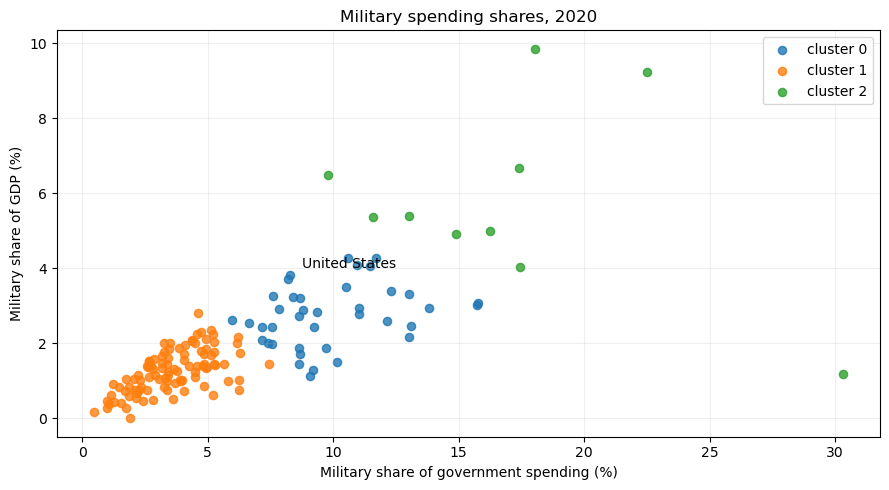

Percent of Government Spending                                                         Percent of GDP                                                        
                                        count    mean     std     min     25%     50%     75%     max          count    mean     std     min     25%     50%     75%     max
cluster_shares                                                                                                                                                              
0                                        39.0  0.0987  0.0241  0.0595  0.0824  0.0920  0.1126  0.1579           39.0  0.0274  0.0082  0.0113  0.0213  0.0278  0.0325  0.0428
1                                        99.0  0.0358  0.0145  0.0049  0.0259  0.0343  0.0474  0.0746           99.0  0.0127  0.0057  0.0001  0.0084  0.0132  0.0168  0.0281
2                                        10.0  0.1713  0.0587  0.0979  0.1350  0.1682  0.1791  0.3030           10.0  0.0581  0.0249  0.0117  0.0493  0.0537  0.0662  0.0985

Mean shares, in percent:
                Percent of Government Spending  Percent of GDP
cluster_shares                                                
0                                         9.87            2.74
1                                         3.58            1.27
2                                        17.13            5.81
Cluster sizes:
cluster_shares
0    39
1    99
2    10
Name: count, dtype: int64
High-share cluster: Algeria, Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait, Oman, Pakistan, Saudi Arabia
                 Country  cluster_spending  cluster_shares
United States of America                 2               0


In [42]:
k_shares = 3
shares_model = KMeans(n_clusters=k_shares, random_state=100, n_init=20)
df2020['cluster_shares'] = shares_model.fit_predict(X_scaled[share_features])

plt.figure(figsize=(9, 5))
for cluster in sorted(df2020['cluster_shares'].unique()):
    sub = df2020[df2020['cluster_shares'] == cluster]
    plt.scatter(100 * sub['Percent of Government Spending'], 100 * sub['Percent of GDP'],
                s=35, alpha=0.8, label=f'cluster {cluster}')
us = df2020[df2020['Country'] == 'United States of America']
plt.annotate('United States',
             (100 * us[share_features[0]].iloc[0], 100 * us[share_features[1]].iloc[0]),
             xytext=(10, 8), textcoords='offset points')
plt.xlabel('Military share of government spending (%)')
plt.ylabel('Military share of GDP (%)')
plt.title('Military spending shares, 2020')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(df2020.groupby('cluster_shares')[share_features].describe().round(4))
print('Mean shares, in percent:')
print((100 * df2020.groupby('cluster_shares')[share_features].mean()).round(2))
print('Cluster sizes:')
print(df2020['cluster_shares'].value_counts().sort_index())
print('High-share cluster:', ', '.join(df2020.loc[df2020['cluster_shares'] == 2, 'Country']))
print(us[['Country', 'cluster_spending', 'cluster_shares']].to_string(index=False))


Cluster 1 is the largest, with 99 countries averaging 3.58% of government spending and 1.27% of GDP on the military. Cluster 0 has 39 countries averaging 9.87% and 2.74%, respectively. Cluster 2 has 10 countries averaging 17.13% of government spending and 5.81% of GDP. It includes Algeria, Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait, Oman, Pakistan, and Saudi Arabia.

These features measure the military's share of available resources rather than the amount of money spent. The U.S. is now in cluster 0 with 38 other countries, rather than being a cluster by itself. Its shares are about 8.20% of government spending and 3.72% of GDP. Norway goes from the high-per-capita cluster in part 2 to the low-share cluster here. A country can spend a lot per person without devoting an unusually large share of its resources to the military.

The two shares generally rise together, but they do not measure the same thing. Belarus has a government spending share of about 30.30% and a GDP share of only 1.16%, so its high-share membership is mainly driven by the first variable. Cluster 2 therefore does not mean every member is high on both measures. The numeric labels are arbitrary and should not be matched directly to the labels in part 2.


### Q2.4 - Clustering on all four variables


    k      SSE
0   1  12.3724
1   2   7.7096
2   3   5.1926
3   4   4.2070
4   5   3.2582
5   6   2.6727
6   7   2.2500
7   8   1.8763
8   9   1.6127
9  10   1.4227


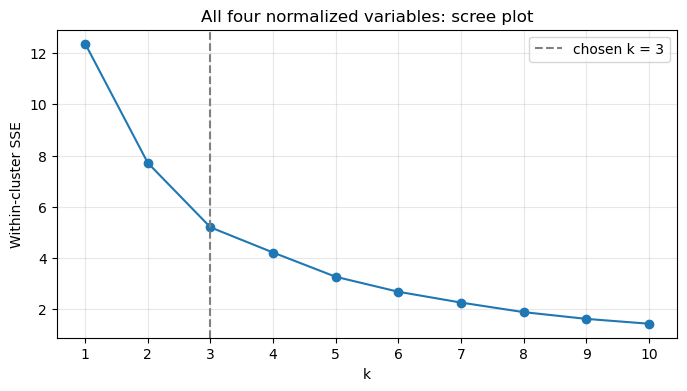

In [43]:
sse_all = []
for k in k_grid:
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X_scaled[features])
    sse_all.append(model.inertia_)

print(pd.DataFrame({'k': list(k_grid), 'SSE': sse_all}).round(4))
plt.figure(figsize=(8, 4))
plt.plot(list(k_grid), sse_all, marker='o')
plt.axvline(3, linestyle='--', color='gray', label='chosen k = 3')
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('All four normalized variables: scree plot')
plt.xticks(list(k_grid))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


I choose $k=3$ again. SSE falls from 12.3724 to 7.7096 to 5.1926, then the next reduction is smaller, to 4.2070 at $k=4$. The elbow is broad rather than exact, so 4 or 5 would give a more detailed partition. I use 3 to summarize the main profiles without assuming every subdivision represents a separate kind of country. SSE levels should be compared within each feature set; the four-variable fit has more distance components than either two-variable fit.


Spending (2020 USD)                                                                                      Spending per Capita                                                        \
                          count         mean          std        min        25%         50%         75%          max               count       mean       std        min        25%        50%   
cluster_all                                                                                                                                                                                      
0                         111.0    7086.4728   26479.3799     8.6225   130.0102    567.6507   3910.1075  257973.4298               111.0   196.9268  267.7885     0.5801    14.8805    67.0834   
1                           6.0  147964.5820  309635.1896  6095.7087  7700.4246  15897.5706  53872.9424  778397.2000                 6.0  1875.1508  489.8002  1193.5987  1645.3019  1780.0596   
2                          31.0    8786.0866   17901.9091   162.3734   467.7879   1404.7872   7739.1662   72937.0640                31.0   212.6891  257.8420    18.2971    46.4859   135.4598   

                                  Percent of Government Spending                                                         Percent of GDP                                                          
                   75%        max                          count    mean     std     min     25%     50%     75%     max          count    mean     std     min     25%     50%     75%     max  
cluster_all                                                                                                                                                                                      
0             295.2961  1341.0589                          111.0  0.0404  0.0193  0.0049  0.0267  0.0380  0.0505  0.0920          111.0  0.0134  0.0060  0.0001  0.0089  0.0136  0.0178  0.0281  
1            2227.3190  2520.3985                            6.0  0.1354  0.0554  0.0820  0.1010  0.1133  0.1645  0.2251            6.0  0.0626  0.0283  0.0294  0.0413  0.0593  0.0854  0.0985  
2             217.3338   998.9662                           31.0  0.1230  0.0439  0.0760  0.0931  0.1148  0.1347  0.3030           31.0  0.0335  0.0114  0.0117  0.0276  0.0320  0.0405  0.0666

Cluster means (share columns shown in percent):
             Spending (2020 USD)  Spending per Capita  Percent of Government Spending  Percent of GDP
cluster_all                                                                                          
0                        7086.47               196.93                            4.04            1.34
1                      147964.58              1875.15                           13.54            6.26
2                        8786.09               212.69                           12.30            3.35
Cluster sizes:
cluster_all
0    111
1      6
2     31
Name: count, dtype: int64
Countries in the high-per-capita cluster:
Israel, Kuwait, Oman, Saudi Arabia, Singapore, United States of America


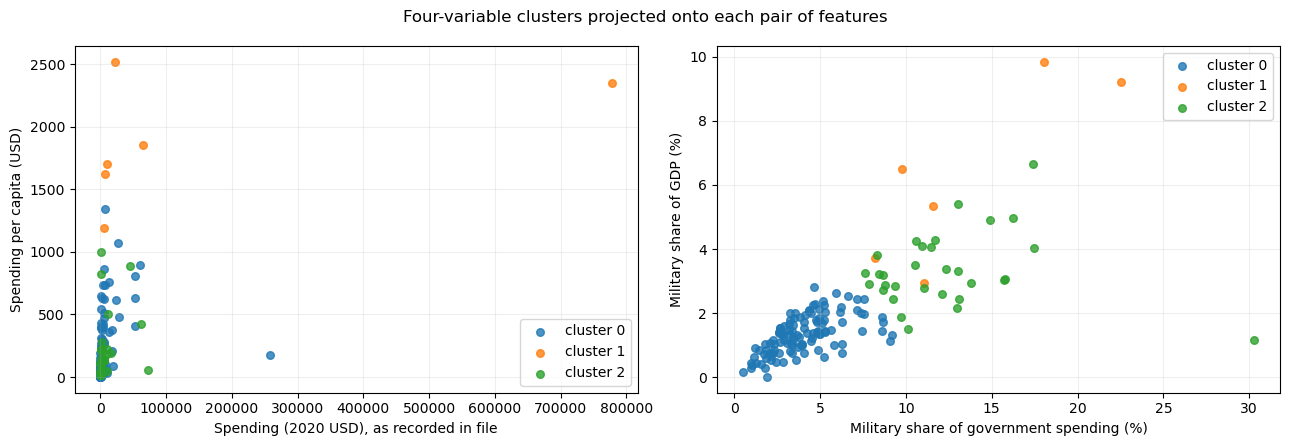

Part 2 vs. all four:
cluster_all        0  1   2
cluster_spending           
0                 85  0  26
1                 25  0   5
2                  0  1   0
3                  1  5   0
Part 3 vs. all four:
cluster_all      0  1   2
cluster_shares           
0               12  2  25
1               99  0   0
2                0  4   6
                 Country  cluster_spending  cluster_shares  cluster_all
United States of America                 2               0            1


In [44]:
k_all = 3
all_model = KMeans(n_clusters=k_all, random_state=100, n_init=20)
df2020['cluster_all'] = all_model.fit_predict(X_scaled[features])

display(df2020.groupby('cluster_all')[features].describe().round(4))
means_all = df2020.groupby('cluster_all')[features].mean()
means_all[share_features] = 100 * means_all[share_features]
print('Cluster means (share columns shown in percent):')
print(means_all.round(2))
print('Cluster sizes:')
print(df2020['cluster_all'].value_counts().sort_index())
print('Countries in the high-per-capita cluster:')
print(', '.join(df2020.loc[df2020['cluster_all'] == 1, 'Country']))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for cluster in sorted(df2020['cluster_all'].unique()):
    sub = df2020[df2020['cluster_all'] == cluster]
    axes[0].scatter(sub[features[0]], sub[features[1]], s=30, alpha=0.8,
                    label=f'cluster {cluster}')
    axes[1].scatter(100 * sub[features[2]], 100 * sub[features[3]], s=30,
                    alpha=0.8, label=f'cluster {cluster}')
axes[0].set_xlabel('Spending (2020 USD), as recorded in file')
axes[0].set_ylabel('Spending per capita (USD)')
axes[1].set_xlabel('Military share of government spending (%)')
axes[1].set_ylabel('Military share of GDP (%)')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.suptitle('Four-variable clusters projected onto each pair of features')
plt.tight_layout()
plt.show()

print('Part 2 vs. all four:')
print(pd.crosstab(df2020['cluster_spending'], df2020['cluster_all']))
print('Part 3 vs. all four:')
print(pd.crosstab(df2020['cluster_shares'], df2020['cluster_all']))
print(df2020.loc[df2020['Country'] == 'United States of America',
                 ['Country', 'cluster_spending', 'cluster_shares', 'cluster_all']].to_string(index=False))


Using all four variables gives a combination of the previous patterns. Cluster 0 contains 111 countries with relatively low average military shares: about 4.04% of government spending and 1.34% of GDP. Their mean per-capita spending is about $197. Cluster 2 has 31 countries averaging higher shares, about 12.30% of government spending and 3.35% of GDP, but similar per-capita spending at about $213. That separation is mainly about resource allocation rather than dollars per person.

Cluster 1 contains Israel, Kuwait, Oman, Saudi Arabia, Singapore, and the United States. They average about $1,875 per person, 13.54% of government spending, and 6.26% of GDP. The U.S. is no longer a singleton because the other dimensions make it similar enough to these countries for a three-cluster summary. Norway, which was in the high-per-capita group in part 2, is now in cluster 0 because of its lower military shares.

The crosstabs show how countries move between the fits without treating cluster numbers as matching categories. The plots show only two-dimensional projections: countries that overlap in one panel can still be separated by the other two features. Also, the change from four clusters in part 2 to three here contributes to the broader grouping, so the difference cannot be attributed only to adding features.


### Q2.5 - Were the patterns useful?


Yes. The most useful distinction is between the size of a military budget, spending per person, and the share of a country's resources devoted to the military. The U.S. is exceptional in total spending, countries such as Norway stand out more per person than by budget share, and countries such as Algeria and Pakistan appear in the high-share group without belonging to the high-per-capita group. Using all four variables brings these different views together.

I would use these clusters as a summary and a starting point for comparisons, not as fixed country classifications. The choice of features, scaling, and $k$ all affect the answer. Min-max scaling prevents the original dollar units from dominating, but it does not remove skewness or outlier influence. The U.S. maximum still compresses most total budgets into a small part of the normalized range, and the two share variables are related, so equal ranges do not mean four independent pieces of information.

Finally, $k$-means will divide even an overlapping cloud into groups, as Q1 showed. The weaker elbows here mean the boundaries should not be overinterpreted. This is also one year's spending among countries with complete data; it does not establish why countries spend differently or measure their actual military capability.


# *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** e0fc6c7db55928791e1b36b0ef50d4264b14294d
- **AI tool and model used:** ChatGPT Sol 6.1

### *Prompts used

### Initial Prompt (ChatGPT Sol 6.1):

I've provided you with the necessary attached files: `notebook.ipynb` and `SIPRI_Military_Expenditure_Database.csv`.

Review the entire notebook, both Q1 and Q2. Do not rewrite it wholesale. I first have to evaluate your suggestions one at a time and make my decision on each, so give me specific, separable changes rather than a rewritten notebook.

Your focus should be on:

Q1: creating the five noise datasets; the scatterplots by group and the explanation of how noise affects visual distinctness; the scree plots for each dataset, the description of how noise affects the elbow, and my ability to select $k$; the intuition of the elbow. Also judge whether my answer addresses how noise affects the *quality* of the clustering, not just the scree plot. For each item, judge both the attempt and the accuracy.

Q2: loading, filtering to 2020, and dropping missing values; whether further cleaning is needed; for Spending and Spending per Capita, the max-min normalization, scree plot, choice of $k$, scatter plot hued by cluster, describe table by cluster, and the short answers (what I see, where the U.S. is, cluster patterns); the same items for Percent of Government Spending and Percent of GDP plus the comparison to part 2; $k$-means on all four variables and the comparison to the previous two parts; whether $k$-MC found useful patterns.

COVERAGE REQUIREMENT: Before proposing any changes, give a one-line verdict for every part below, in this order, using exactly one of: **No change needed** (state why in one clause), **Change proposed** (reference the change number), or **Unsure** (say what you could not verify). Do not skip any part, including Q1. A part with no verdict counts as an incomplete review.

Q1.1, Q1.2, Q1.3, Q1.4, Q2.1, Q2.2, Q2.3, Q2.4, Q2.5

For each change you propose, give me:

1. A one-line description of the change.
2. Which item it affects.
3. Severity: correctness bug, quality improvement, or style.
4. The actual numeric/percentage change.
5. Whether it changes any number I currently report in a markdown answer.

Run the code to verify every number you give me. If you assert a number you did not compute, label it as an estimate.

Separately, at the end, list:
- Anything in my markdown explanations that is contradicted by the notebook's own printed output.
- Any clustering or cleaning decision I made that you consider correct but would have done differently, and why.
- Anything you are genuinely unsure about.

Finish with a concise numbered list of your proposed changes, one line each, that I can paste into my notebook verbatim as your recommendations as Phase 2 of the notebook directly requests.

### Follow Up Prompts:

I reviewed your recommendations. My decisions:

- **Change 1: Approved, with one addition.** Alongside ARI, report the number of misassigned points out of 150 after optimally matching cluster labels to groups (I get 0, 0, 1, 27, 64). ARI has no intuitive scale on its own.
- **Change 2: Approved, with one addition.** Also print the median implied ratio across all 148 countries (33.84%) and the next-lowest value (11.96%) so the reader can see how far the two flagged countries sit from everyone else.
- **Change 3: Approved as a separate sensitivity analysis.** Do not replace the main analysis. Add the direction of each move and what does not change: Angola moves from the 99-country low-share cluster into the 39-country cluster; all six four-variable movers move from the 111-country cluster into the 31-country cluster; the other nine high-share countries and the six-country high-per-capita cluster are unchanged. Also state that removing Belarus lowers the maximum government-spending share from 30.30% to 22.51% (Saudi Arabia) and removing Zimbabwe raises the minimum GDP share from 0.0054% to 0.16%, which is why the rescaled fits shift.
- **Change 4: Approved as proposed.**
- **Your note that "about 32%" in Q2.3 is a typo: rejected.** The exact reduction is 31.82%, which rounds to 32%, so the wording stays.
- **Your uncertainty about units: resolved.** Spending (2020 USD) divided by Spending per Capita gives implied populations of 1,439.3 million for China, 331.0 million for the U.S., and 1,380.0 million for India, which confirms total spending is in millions of USD. "Constant 2020 dollars" comes from the column name and should be described that way.

Now write the complete Phase 2 solution for Q1 and Q2 from your own perspective, incorporating the approved changes above. Requirements:

- Cover every part: Q1.1–Q1.4 and Q2.1–Q2.5. Parts with no approved change still get a full answer (code and markdown). Do not skip Q1 and do not write "unchanged from Phase 1."
- Keep my existing choices of $k$ (4, 3, 3), `random_state=100`, `n_init=20`, and min-max scaling. Keep the main analysis on all 148 countries.
- Output notebook cells in order, each labeled [code] or [markdown], ready to paste. The data path is `./data/SIPRI Military Expenditure Database.csv`.
- Run all of the code and make sure every number in the markdown matches the printed output. Label anything you did not compute as an estimate.
- Do not modify or reproduce the Phase 1 section, and do not write the reflection.
- At the top, list which parts changed relative to Phase 1 and which approved change each one implements.

### *AI-proposed changes


The models returned ten recommendations across one rounds. Round 1 is ChatGPT Sol 6.1's review; its coverage verdicts and its four-item list are reproduced exactly as returned, using its own numbering. The evaluation that follows refers to these as changes A–F and 1–4.

### Round 1 — coverage verdicts, ChatGPT Sol 6.1

| Part | Verdict |
|---|---|
| Q1.1 | No change needed (all five datasets are generated correctly with the required noise levels). |
| Q1.2 | No change needed (the group scatterplots and explanation accurately describe increasing overlap). |
| Q1.3 | Change proposed (Change 1). |
| Q1.4 | No change needed (the elbow explanation correctly distinguishes capturing groups from subdividing noise). |
| Q2.1 | Change proposed (Changes 2 and 3). |
| Q2.2 | No change needed (normalization, scree plot, choice of $k$, scatterplot, describe table, and interpretations are correct). |
| Q2.3 | Change proposed (Changes 3 and 4). |
| Q2.4 | Change proposed (Change 3). |
| Q2.5 | No change needed (the usefulness assessment is supported and acknowledges the method's limitations). |

### Round 1 — proposed changes, ChatGPT Sol 6.1 (changes 1–4)

1. Add a fixed-k=3 adjusted Rand index comparison in Q1.3 to show explicitly how increasing noise reduces recovery of the known generating groups.
2. Print the implied government-spending-to-GDP ratios for Belarus and Zimbabwe in Q2.1 to verify the cleaning concerns stated in the explanation.
3. Add a separate sensitivity analysis excluding Belarus and Zimbabwe, refitting min-max scaling, and comparing cluster memberships with the original fits after matching cluster labels.
4. Correct Belarus's GDP share in Q2.3 from 1.16% to 1.17%.

### *Evaluation of AI suggestions


Every figure in both rounds was recomputed independently from the raw CSV before a decision was recorded. All of ChatGPT's numbers reproduced exactly, including the five ARI values, both implied ratios, the 146-country sensitivity sample, and the names of the seven countries that change membership. The decisions below therefore turn on scope and interpretation rather than arithmetic. Of the ten, five were accepted as proposed (A, B, 4) or with additions (D, 1, 2, 3), one was superseded (C), and two were rejected (E, F).

ChatGPT's assessment table called "about 32%" in Q2.3 a typo, but the exact reduction is 31.82%, which rounds to 32%, so I kept my wording. ChatGPT also listed the spending units as unverifiable from the file. They are verifiable, as shown under change D.

| Change | Decision | Reason and verification |
|---|---|---|
| A | **Approved as proposed** | Verified: the ratio is **0.2851%** for Zimbabwe and **3.8748%** for Belarus, against a median of **33.84%** across the 148 countries. The next-lowest value is **11.96%**. Phase 1 said no further cleaning was needed and missed both. I rewrote Q2.1 to flag them and keep them, since the file offers no verified replacement. Belarus matters for scaling because it sets the maximum government-spending share at **30.30%**; the next highest is Saudi Arabia at **22.51%**. |
| B | **Superseded by change 1** | Same recommendation. ChatGPT computed the numbers in Round 1, so the decision and verification are recorded under change 1. |
| C | **Modified, then approved** | Verified: spending ÷ spending per capita gives implied populations of **1,439.3M** (China), **331.0M** (U.S.), and **1,380.0M** (India). Those match the real populations only if spending is in millions. Modified because "constant 2020 dollars" rests on the column name, not on anything the file can check, so Q2.1 attributes it to the column name. This also resolves the units uncertainty ChatGPT raised in Round 1. |
| D | **Rejected** | Presentation only: log axes change no fit, no label, and no reported number, and the question asks for a scatterplot of the two variables as given. ChatGPT's review judged the existing plots correct. I kept the raw axes. |
| E | **Rejected** | The arithmetic holds: SSE falls from **0.6294 to 0.4131**, a **34.4%** drop. But Q2.2 already justifies $k=4$, ChatGPT independently judged it defensible, and a silhouette score would add a second selection criterion the assignment does not ask for. |
| 1 | **Modified, then approved** | Verified ARI at $k=3$: **1.0000, 1.0000, 0.9799, 0.5459, 0.2062** for noise 0.125 through 2.0. Modified to also report misassigned points after optimally matching labels to groups: **0, 0, 1, 27, and 64 of 150** (100%, 100%, 99.33%, 82.00%, 57.33% recovered), because ARI has no intuitive scale. This closes the gap in Phase 1, which addressed "quality" only through the scree plots. Even with the correct $k$, recovery collapses between noise 0.5 and 1.0. |
| 2 | **Modified, then approved** | Verified: **3.8748%** (Belarus) and **0.2851%** (Zimbabwe), matching the rounded figures in Q2.1. Modified to also print the median (**33.84%**) and the next-lowest value (**11.96%**). Without a reference point, 3.87% does not read as anomalous. |
| 3 | **Modified, then approved** | Verified: **146** countries; **0/146** changes for spending, **1/146** for shares (Angola), and **6/146** for all four variables (Bangladesh, Gabon, Guinea, Niger, Sri Lanka, Sudan) after optimal label matching. Modified because counts alone do not say whether any conclusion changes. Angola moves from the 99-country low-share cluster into the 39-country cluster. All six four-variable movers go from the 111-country cluster into the 31-country cluster. The other nine high-share countries and the six-country high-per-capita cluster are unchanged, so no headline finding depends on the flagged rows. The cause is the rescaling: removing Belarus lowers the maximum government share from **30.30% to 22.51%**, and removing Zimbabwe raises the minimum GDP share from **0.0054% to 0.16%**. ChatGPT's caveat that removal and refitting the scaler are confounded is correct. Kept as a separate sensitivity analysis; the main analysis stays at 148 countries. |
| 4 | **Approved as proposed** | Verified: Belarus's Percent of GDP is **0.011742**, which is **1.17%**, and it is the high-share cluster's minimum GDP share (**0.0117**) in my own printed describe table. A rounding error of mine, corrected. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [45]:
# Phase 2 solution. All answers below for Q1 and Q2 were generated by ChatGPT Sol 6.1,
# incorporating the approved and modified changes from the evaluation above.
# Every figure was rerun and checked against the raw CSV before submission.

# Q1. Noise and $k$-Means Clustering

### Q1.1 - Create the datasets

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N),
                   np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N),
                   np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N),
                   np.random.normal(3, noise, N)])

    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

print(pd.DataFrame({
    noise: data['group'].value_counts()
    for noise, data in datasets.items()
}))

       0.125  0.250  0.500  1.000  2.000
group                                   
a         50     50     50     50     50
b         50     50     50     50     50
c         50     50     50     50     50


The supplied code creates five datasets, despite the prompt saying four. Each contains 150 points, with 50 points per group. The generating centers remain at (1, 1), (3, 2), and (5, 3), while the standard deviation increases.

Resetting the seed inside the function means the datasets use the same underlying random draws, scaled by the noise level. This makes the effect of increasing noise easier to compare.

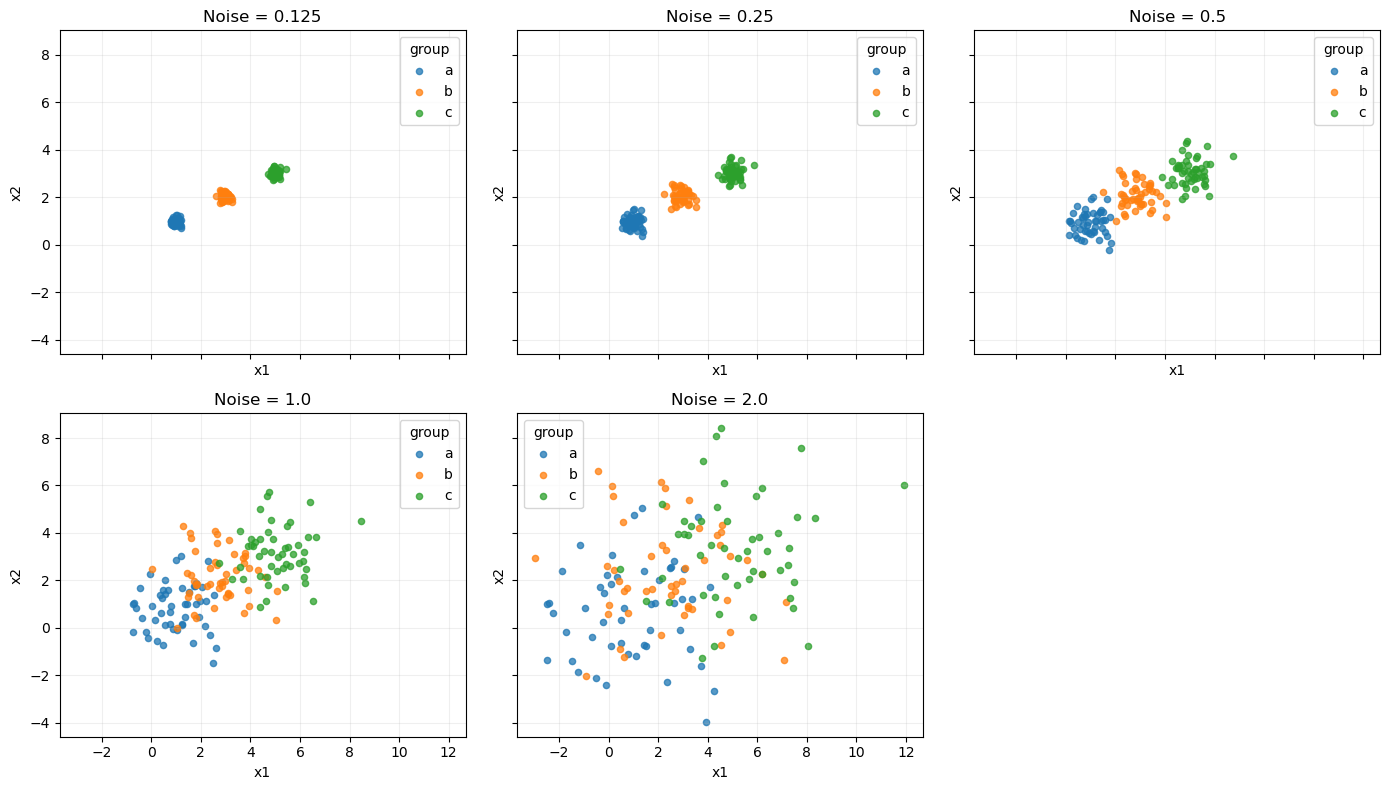

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)

for ax, (noise, data) in zip(axes.flat, datasets.items()):
    for group in ['a', 'b', 'c']:
        sub = data[data['group'] == group]
        ax.scatter(sub['x1'], sub['x2'], s=20, alpha=0.75, label=group)
    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend(title='group')
    ax.grid(alpha=0.2)

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

At noise 0.125 and 0.25, the groups form three tight clouds with clear gaps between them. At 0.5, the clouds spread toward each other, but the groups remain mostly distinct. At 1.0, neighboring groups overlap substantially. At 2.0, the colors are mixed together, making three separate clusters difficult to identify by eye.

The generating centers remain fixed. What increases is the spread around each center relative to the distance between centers. With enough noise, a point generated by one group can be closer to another group's center than to its own.

### Q1.3 - Scree plots, choosing $k$, and clustering quality

     0.125   0.250   0.500   1.000    2.000
k                                          
1   511.61  533.25  606.62  873.69  1889.20
2   128.89  142.72  186.78  361.59  1071.81
3     4.91   19.65   77.78  254.88   790.48
4     4.33   17.33   67.19  210.15   591.18
5     3.76   15.08   58.67  174.92   498.19
6     3.26   12.89   50.32  147.21   418.79
7     2.79   11.17   43.05  123.19   356.70
8     2.45    9.70   36.63  105.92   303.69
9     2.11    8.24   32.66   93.56   264.42
10    1.88    7.47   29.67   82.42   237.28


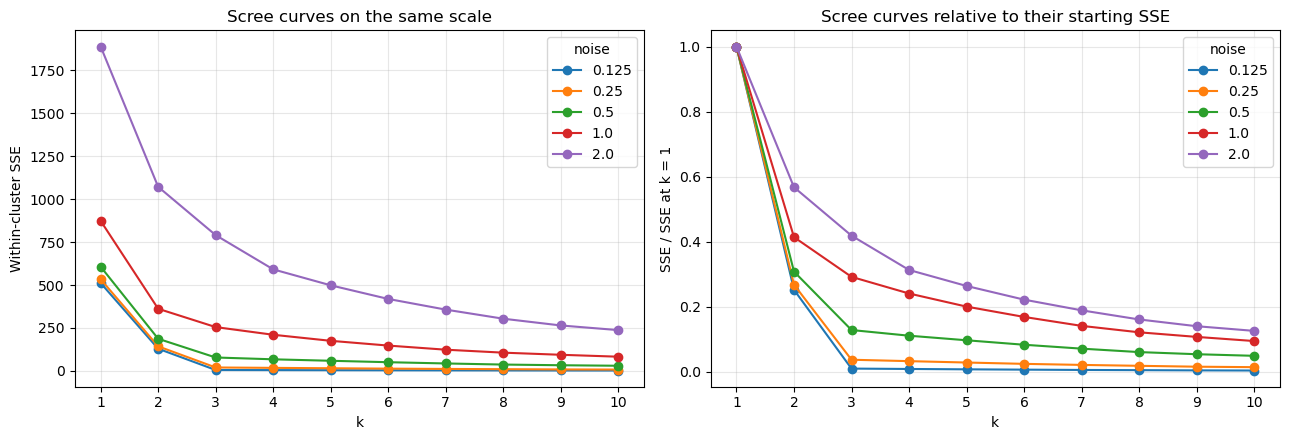

Recovery of generating groups at fixed k = 3:
 noise    ARI  misassigned  total  misassigned (%)
 0.125 1.0000            0    150           0.0000
 0.250 1.0000            0    150           0.0000
 0.500 0.9799            1    150           0.6667
 1.000 0.5459           27    150          18.0000
 2.000 0.2062           64    150          42.6667


In [48]:
k_grid = range(1, 11)
sse_noise = pd.DataFrame(index=list(k_grid))

for noise, data in datasets.items():
    sse = []
    for k in k_grid:
        model = KMeans(n_clusters=k, random_state=100, n_init=20)
        model.fit(data[['x1', 'x2']])
        sse.append(model.inertia_)
    sse_noise[noise] = sse

sse_noise.index.name = 'k'
print(sse_noise.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for noise in datasets:
    axes[0].plot(
        sse_noise.index, sse_noise[noise],
        marker='o', label=noise
    )
    axes[1].plot(
        sse_noise.index,
        sse_noise[noise] / sse_noise.loc[1, noise],
        marker='o', label=noise
    )

axes[0].set_ylabel('Within-cluster SSE')
axes[0].set_title('Scree curves on the same scale')
axes[1].set_ylabel('SSE / SSE at k = 1')
axes[1].set_title('Scree curves relative to their starting SSE')

for ax in axes:
    ax.set_xlabel('k')
    ax.set_xticks(list(k_grid))
    ax.legend(title='noise')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

quality_rows = []

for noise, data in datasets.items():
    labels = KMeans(
        n_clusters=3, random_state=100, n_init=20
    ).fit_predict(data[['x1', 'x2']])

    # Match arbitrary cluster labels to generating groups.
    counts = pd.crosstab(data['group'].to_numpy(), labels).to_numpy()
    rows, cols = linear_sum_assignment(-counts)
    misassigned = len(data) - counts[rows, cols].sum()

    quality_rows.append({
        'noise': noise,
        'ARI': adjusted_rand_score(data['group'], labels),
        'misassigned': misassigned,
        'total': len(data),
        'misassigned (%)': 100 * misassigned / len(data)
    })

quality = pd.DataFrame(quality_rows)
print('Recovery of generating groups at fixed k = 3:')
print(quality.round(4).to_string(index=False))

With noise 0.125, SSE falls from 511.61 at $k=1$ to 128.89 at $k=2$ and 4.91 at $k=3$, then only to 4.33 at $k=4$. This gives a clear elbow at 3. The same pattern holds at 0.25. At 0.5, the elbow at 3 remains reasonably clear, although the remaining SSE is higher.

At noise 1.0, SSE is 873.69, 361.59, 254.88, and 210.15 for $k=1,2,3,4$. Most of the improvement occurs from 1 to 2, and there is no equally sharp stopping point at 3. At noise 2.0, the curve bends more gradually. A choice around 2 or 3 could be defended from the noisier curves, but the elbow does not definitively identify the number of generating groups.

The common vertical scale shows that more noise leaves much more within-cluster error. The relative plot makes the shapes easier to compare without the highest-noise dataset dominating the graph.

Noise also reduces the quality of clustering when quality means recovering the original generating groups. Holding $k=3$ fixed gives:

| Noise | ARI | Misassigned points | Misassigned percentage |
|---|---:|---:|---:|
| 0.125 | 1.0000 | 0/150 | 0.00% |
| 0.25 | 1.0000 | 0/150 | 0.00% |
| 0.5 | 0.9799 | 1/150 | 0.67% |
| 1.0 | 0.5459 | 27/150 | 18.00% |
| 2.0 | 0.2062 | 64/150 | 42.67% |

ARI compares the fitted partition with the generating groups while accounting for chance agreement. An ARI of 1 means the partitions agree perfectly. The misassignment count is easier to interpret directly: after optimally matching cluster labels to groups, it counts points assigned to a different group.

These results show that even when the algorithm is given the true generating $k$, increasing overlap makes the original groups harder to recover. This is separate from the increasing difficulty of choosing $k$ from the scree plot. The known group labels are used only for evaluation, never as clustering features.

### Q1.4 - Intuition of the elbow

$k$-means minimizes the sum of squared distances from observations to their assigned centers:

$$
\mathrm{SSE}
=
\sum_{j=1}^{k}
\sum_{i\in C_j}
\lVert x_i-\mu_j\rVert^2.
$$

With one center, the model represents all three clouds with one point. Adding a second center removes much of the distance between groups. Adding a third allows each tight cloud to have its own center. After that structure has been captured, additional centers mostly divide the random variation within the clouds, so each extra center helps much less. This transition from large improvements to small improvements creates the elbow.

When the clouds overlap, capturing another generating group and subdividing an existing cloud become harder to distinguish. Additional centers continue reducing error, but the stopping point becomes less obvious.

SSE alone cannot select $k$ by taking its minimum because adding centers generally reduces SSE. The elbow instead looks for diminishing returns. It is a judgment about a useful level of detail, not a guarantee that the original groups have been recovered.

# Q2. Military Spending Clusters

### Q2.1 - Load and clean the 2020 data

In [49]:
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df2020 = df.loc[df['Year'] == 2020].copy()

print('all years:', df.shape)
print('2020 before dropping missing:', df2020.shape)
print(df2020.isna().sum())

df2020 = df2020.dropna().copy()
df2020 = df2020.drop(columns=['index']).reset_index(drop=True)
df2020['Country'] = df2020['Country'].str.strip()

features = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

print('2020 complete cases:', df2020.shape)
print('duplicate countries:', df2020['Country'].duplicated().sum())
print('negative values:', (df2020[features] < 0).sum().sum())
print('infinite values:', np.isinf(df2020[features]).sum().sum())
print(df2020[features].dtypes)
print(df2020[features].describe().round(4))
display(df2020.head())

implied_gov_pct = (
    100 * df2020['Percent of GDP']
    / df2020['Percent of Government Spending']
)

audit = df2020[['Country']].copy()
audit['Military / government (%)'] = (
    100 * df2020['Percent of Government Spending']
)
audit['Military / GDP (%)'] = 100 * df2020['Percent of GDP']
audit['Implied government / GDP (%)'] = implied_gov_pct

print('Three lowest implied government-to-GDP ratios:')
print(
    audit.nsmallest(3, 'Implied government / GDP (%)')
    .round(4).to_string(index=False)
)
print(
    'Median implied government / GDP (%):',
    round(implied_gov_pct.median(), 2)
)

print('Implied population (millions):')
population_check = df2020.loc[
    df2020['Country'].isin(['China', 'United States of America', 'India']),
    ['Country'] + features[:2]
].copy()

population_check['Population (millions)'] = (
    population_check[features[0]] / population_check[features[1]]
)
print(
    population_check[['Country', 'Population (millions)']]
    .round(1).to_string(index=False)
)

all years: (5882, 7)
2020 before dropping missing: (173, 7)
index                              0
Year                               0
Country                            0
Spending (2020 USD)               23
Percent of GDP                    23
Percent of Government Spending    25
Spending per Capita               24
dtype: int64
2020 complete cases: (148, 6)
duplicate countries: 0
negative values: 0
infinite values: 0
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  Percent of Government Spending  Percent of GDP
count             148.0000             148.0000                        148.0000        148.0000
mean            13153.7477             268.2645                          0.0615          0.0196
std             68005.2361             430.4349                          0.0462          0.0150
min        

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
1,2020,Albania,187.433234,0.012583,0.037952,65.126211
2,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
3,2020,Angola,993.594405,0.014442,0.074624,30.231680
4,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


Three lowest implied government-to-GDP ratios:
  Country  Military / government (%)  Military / GDP (%)  Implied government / GDP (%)
 Zimbabwe                     1.8941              0.0054                        0.2851
  Belarus                    30.3027              1.1742                        3.8748
Congo, DR                     6.2685              0.7495                       11.9558
Median implied government / GDP (%): 33.84
Implied population (millions):
                 Country  Population (millions)
                   China                 1439.3
                   India                 1380.0
United States of America                  331.0


The file contains 5,882 rows across all years. Filtering to 2020 gives 173 rows, and dropping rows with missing values leaves 148 countries. I remove the old index column because it is a row identifier and exclude Country and Year from the clustering features. The complete cases contain no duplicate countries, negative feature values, or infinite feature values. All four features load as numeric.

Spending (2020 USD) is measured in millions of constant 2020 U.S. dollars, while Spending per Capita is measured in dollars per person. Dividing total spending by spending per capita gives implied populations of 1,439.3 million for China, 331.0 million for the U.S., and 1,380.0 million for India, supporting the millions-of-dollars interpretation. The column name identifies the dollar basis as 2020 dollars.

Both percentage columns are stored as proportions, so multiplying by 100 expresses them as percentages.

Further checks are useful even though the variables are numeric. If the two military-spending shares use compatible definitions, their ratio implies total government spending as a share of GDP:

$$
\frac{M/GDP}{M/G}=\frac{G}{GDP}.
$$

Zimbabwe's implied ratio is 0.29%, and Belarus's is 3.87%. The next-lowest value is 11.96% for Congo, DR, while the median across all 148 countries is 33.84%. This makes the two flagged observations stand out from the rest of the sample.

These values suggest possible reporting, unit, or denominator inconsistencies, but the file alone does not establish their cause. I retain both countries in the main analysis because an unusual observation is not automatically an error and there are no verified replacement values. A separate sensitivity analysis after Q2.4 checks how excluding them affects the results.

Finally, I min-max normalize the features before clustering so that their different units and ranges do not dominate the distance calculation.

### Q2.2 - Total spending and spending per capita

     Spending (2020 USD)  Spending per Capita  Percent of Government Spending  Percent of GDP
min                  0.0                  0.0                             0.0             0.0
max                  1.0                  1.0                             1.0             1.0
    k     SSE
0   1  5.4114
1   2  2.4353
2   3  1.3218
3   4  0.6294
4   5  0.4131
5   6  0.3070
6   7  0.2116
7   8  0.1471
8   9  0.1038
9  10  0.0856


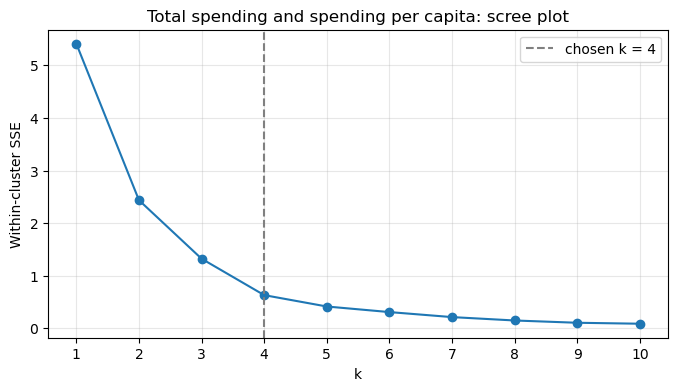

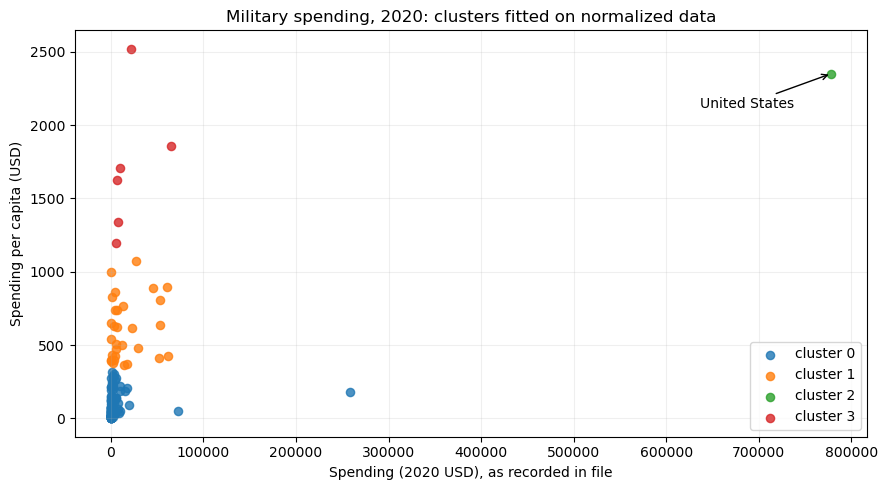

Spending (2020 USD)                                                                             Spending per Capita                                                              
                               count       mean       std        min        25%        50%        75%        max               count     mean     std      min      25%      50%      75%      max
cluster_spending                                                                                                                                                                                  
0                              111.0    4859.19  25405.74       8.62     130.01     382.46    2297.03  257973.43               111.0    80.06   83.50     0.58    14.88    47.06   125.39   314.20
1                               30.0   17077.59  20583.05     405.79    2294.04    5857.06   26296.00   61712.54                30.0   607.48  206.93   362.47   422.21   579.00   757.33  1070.62
2                                1.0  778397.20       NaN  778397.20  778397.20  778397.20  778397.20  778397.20                 1.0  2351.63     NaN  2351.63  2351.63  2351.63  2351.63  2351.63
3                                6.0   19443.36  22861.51    6095.71    7023.25    8624.23   18857.07   64558.40                 6.0  1706.72  466.38  1193.60  1412.08  1665.45  1817.22  2520.40

Countries in the smaller clusters:
1 : Australia, Austria, Bahrain, Belgium, Brunei, Canada, Cyprus, Denmark, Estonia, Finland, France, Germany, Greece, Italy, Japan, Korea, South, Latvia, Lithuania, Luxembourg, Netherlands, New Zealand, Poland, Portugal, Russia, Slovakia, Spain, Sweden, Switzerland, Taiwan, United Kingdom
2 : United States of America
3 : Israel, Kuwait, Norway, Oman, Saudi Arabia, Singapore
                 Country  cluster_spending
United States of America                 2


In [50]:
# Preserve original units in df2020 for interpretation.
X_scaled = (df2020[features] - df2020[features].min()) / (
    df2020[features].max() - df2020[features].min()
)

print(X_scaled.agg(['min', 'max']).round(3))

spending_features = features[:2]
sse_spending = []

for k in k_grid:
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X_scaled[spending_features])
    sse_spending.append(model.inertia_)

print(pd.DataFrame({
    'k': list(k_grid), 'SSE': sse_spending
}).round(4))

plt.figure(figsize=(8, 4))
plt.plot(list(k_grid), sse_spending, marker='o')
plt.axvline(4, linestyle='--', color='gray', label='chosen k = 4')
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('Total spending and spending per capita: scree plot')
plt.xticks(list(k_grid))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

k_spending = 4
spending_model = KMeans(
    n_clusters=k_spending, random_state=100, n_init=20
)
df2020['cluster_spending'] = spending_model.fit_predict(
    X_scaled[spending_features]
)

plt.figure(figsize=(9, 5))

for cluster in sorted(df2020['cluster_spending'].unique()):
    sub = df2020[df2020['cluster_spending'] == cluster]
    plt.scatter(
        sub['Spending (2020 USD)'], sub['Spending per Capita'],
        s=35, alpha=0.8, label=f'cluster {cluster}'
    )

us = df2020[df2020['Country'] == 'United States of America']
plt.annotate(
    'United States',
    (us['Spending (2020 USD)'].iloc[0],
     us['Spending per Capita'].iloc[0]),
    xytext=(-95, -25), textcoords='offset points',
    arrowprops={'arrowstyle': '->'}
)
plt.xlabel('Spending (2020 USD), as recorded in file')
plt.ylabel('Spending per capita (USD)')
plt.title('Military spending, 2020: clusters fitted on normalized data')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(
    df2020.groupby('cluster_spending')[spending_features]
    .describe().round(2)
)

print('Countries in the smaller clusters:')
for cluster in [1, 2, 3]:
    print(
        cluster, ':',
        ', '.join(
            df2020.loc[
                df2020['cluster_spending'] == cluster, 'Country'
            ]
        )
    )

print(us[['Country', 'cluster_spending']].to_string(index=False))

I choose $k=4$. SSE falls from 5.4114 to 2.4353 to 1.3218 to 0.6294 for $k=1,2,3,4$. The next improvement is smaller, reaching 0.4131 at $k=5$. Three clusters would be a reasonable simpler alternative, but four captures another substantial improvement before the curve levels out. The elbow does not establish a unique mathematical optimum.

Cluster 0 contains 111 countries with mean spending per capita of $80.06. Cluster 1 contains 30 countries averaging $607.48 per person, including many European countries, Australia, Canada, Japan, and South Korea. Cluster 3 contains Israel, Kuwait, Norway, Oman, Saudi Arabia, and Singapore, averaging $1,706.72 per person.

The U.S. is alone in cluster 2. Its total spending is 778,397.2 million constant 2020 dollars, and its spending per capita is $2,351.63. Israel spends more per person, at $2,520.40, but the U.S. stands far above the other countries in total spending. The singleton's standard deviation is NaN because one observation does not have a sample standard deviation.

Most of the remaining separation follows spending per capita. China belongs to cluster 0 despite having the second-largest total budget because its spending per capita is only about $179. Min-max normalization gives both features the same range, but the U.S. maximum compresses most other countries' normalized total spending toward zero.

A low-per-capita cluster therefore does not necessarily indicate a small total military budget. These groups describe spending profiles, not military effectiveness or alliances. The describe table retains the original units so the differences remain interpretable.

### Q2.3 - Government spending share and GDP share

    k     SSE
0   1  6.9609
1   2  2.9274
2   3  1.9958
3   4  1.4745
4   5  1.0728
5   6  0.8033
6   7  0.6462
7   8  0.5325
8   9  0.4450
9  10  0.3857


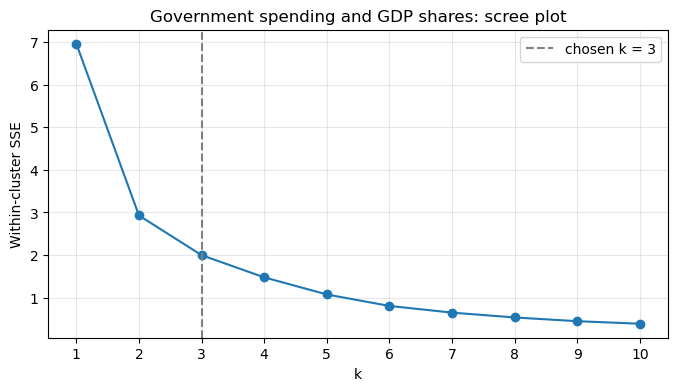

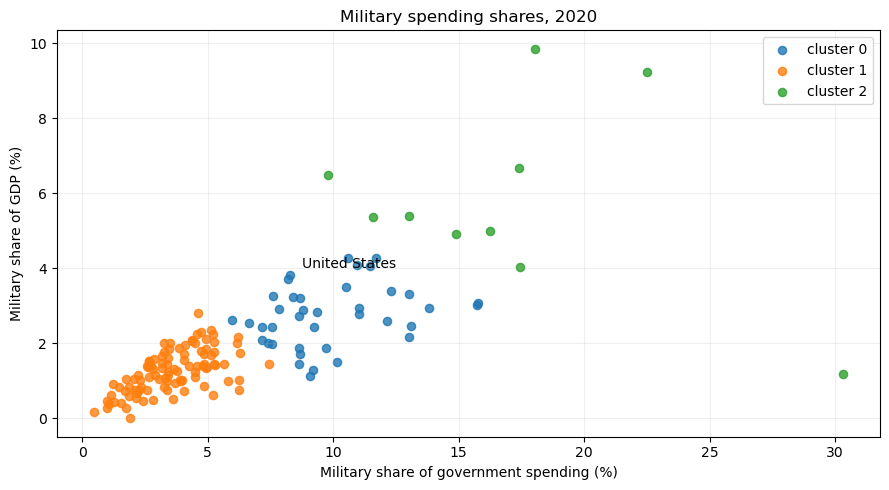

Percent of Government Spending                                                         Percent of GDP                                                        
                                        count    mean     std     min     25%     50%     75%     max          count    mean     std     min     25%     50%     75%     max
cluster_shares                                                                                                                                                              
0                                        39.0  0.0987  0.0241  0.0595  0.0824  0.0920  0.1126  0.1579           39.0  0.0274  0.0082  0.0113  0.0213  0.0278  0.0325  0.0428
1                                        99.0  0.0358  0.0145  0.0049  0.0259  0.0343  0.0474  0.0746           99.0  0.0127  0.0057  0.0001  0.0084  0.0132  0.0168  0.0281
2                                        10.0  0.1713  0.0587  0.0979  0.1350  0.1682  0.1791  0.3030           10.0  0.0581  0.0249  0.0117  0.0493  0.0537  0.0662  0.0985

Mean shares, in percent:
                Percent of Government Spending  Percent of GDP
cluster_shares                                                
0                                         9.87            2.74
1                                         3.58            1.27
2                                        17.13            5.81
Cluster sizes:
cluster_shares
0    39
1    99
2    10
Name: count, dtype: int64
High-share cluster: Algeria, Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait, Oman, Pakistan, Saudi Arabia
                 Country  cluster_spending  cluster_shares
United States of America                 2               0
SSE reduction from k = 2 to k = 3 (%): 31.82
Belarus military / GDP (%): 1.17


In [51]:
share_features = features[2:]
sse_shares = []

for k in k_grid:
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X_scaled[share_features])
    sse_shares.append(model.inertia_)

print(pd.DataFrame({
    'k': list(k_grid), 'SSE': sse_shares
}).round(4))

plt.figure(figsize=(8, 4))
plt.plot(list(k_grid), sse_shares, marker='o')
plt.axvline(3, linestyle='--', color='gray', label='chosen k = 3')
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('Government spending and GDP shares: scree plot')
plt.xticks(list(k_grid))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

k_shares = 3
shares_model = KMeans(
    n_clusters=k_shares, random_state=100, n_init=20
)
df2020['cluster_shares'] = shares_model.fit_predict(
    X_scaled[share_features]
)

plt.figure(figsize=(9, 5))

for cluster in sorted(df2020['cluster_shares'].unique()):
    sub = df2020[df2020['cluster_shares'] == cluster]
    plt.scatter(
        100 * sub['Percent of Government Spending'],
        100 * sub['Percent of GDP'],
        s=35, alpha=0.8, label=f'cluster {cluster}'
    )

us = df2020[df2020['Country'] == 'United States of America']
plt.annotate(
    'United States',
    (100 * us[share_features[0]].iloc[0],
     100 * us[share_features[1]].iloc[0]),
    xytext=(10, 8), textcoords='offset points'
)
plt.xlabel('Military share of government spending (%)')
plt.ylabel('Military share of GDP (%)')
plt.title('Military spending shares, 2020')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(
    df2020.groupby('cluster_shares')[share_features]
    .describe().round(4)
)

print('Mean shares, in percent:')
print(
    (100 * df2020.groupby('cluster_shares')[share_features].mean())
    .round(2)
)
print('Cluster sizes:')
print(df2020['cluster_shares'].value_counts().sort_index())

print(
    'High-share cluster:',
    ', '.join(
        df2020.loc[df2020['cluster_shares'] == 2, 'Country']
    )
)
print(
    us[['Country', 'cluster_spending', 'cluster_shares']]
    .to_string(index=False)
)

print(
    'SSE reduction from k = 2 to k = 3 (%):',
    round(100 * (sse_shares[1] - sse_shares[2]) / sse_shares[1], 2)
)
print(
    'Belarus military / GDP (%):',
    round(
        100 * df2020.loc[
            df2020['Country'].eq('Belarus'), 'Percent of GDP'
        ].iloc[0],
        2
    )
)

I choose $k=3$ as a simple low-, middle-, and high-share summary. SSE falls from 6.9609 to 2.9274 to 1.9958 for $k=1,2,3$, then to 1.4745 at 4. The elbow is less sharp than in part 2, and $k=2$ is also defensible. The third center removes about 32% of the remaining SSE; the computed reduction is 31.82%. I would not interpret these as three sharply separated natural types of countries.

Cluster 1 contains 99 countries averaging 3.58% of government spending and 1.27% of GDP on the military. Cluster 0 contains 39 countries averaging 9.87% and 2.74%, respectively. Cluster 2 contains 10 countries averaging 17.13% of government spending and 5.81% of GDP. Its members are Algeria, Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait, Oman, Pakistan, and Saudi Arabia.

These variables describe the military's share of available resources rather than the amount of money spent. The U.S. belongs to cluster 0 with 38 other countries instead of forming its own cluster. Its shares are about 8.20% of government spending and 3.72% of GDP. Norway moves from the high-per-capita group in part 2 to the low-share group here. A country can spend a lot per person without allocating an unusually large share of its resources to the military.

The shares generally rise together, but they measure different things. Belarus has a government-spending share of about 30.30% and a GDP share of only 1.17%, so its high-share membership is mainly driven by the first variable. Membership in cluster 2 does not mean every country is high on both measures.

Cluster labels are arbitrary and should not be matched directly to the labels from part 2. The separate sensitivity analysis below checks how the flagged observations affect this partition.

### Q2.4 - Clustering on all four variables

    k      SSE
0   1  12.3724
1   2   7.7096
2   3   5.1926
3   4   4.2070
4   5   3.2582
5   6   2.6727
6   7   2.2500
7   8   1.8763
8   9   1.6127
9  10   1.4227


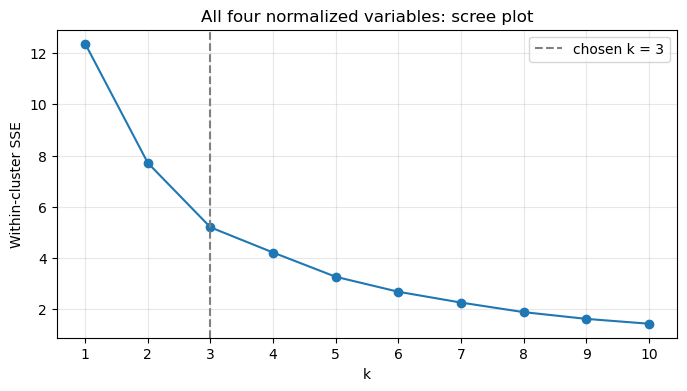

Spending (2020 USD)                                                                                      Spending per Capita                                                        \
                          count         mean          std        min        25%         50%         75%          max               count       mean       std        min        25%        50%   
cluster_all                                                                                                                                                                                      
0                         111.0    7086.4728   26479.3799     8.6225   130.0102    567.6507   3910.1075  257973.4298               111.0   196.9268  267.7885     0.5801    14.8805    67.0834   
1                           6.0  147964.5820  309635.1896  6095.7087  7700.4246  15897.5706  53872.9424  778397.2000                 6.0  1875.1508  489.8002  1193.5987  1645.3019  1780.0596   
2                          31.0    8786.0866   17901.9091   162.3734   467.7879   1404.7872   7739.1662   72937.0640                31.0   212.6891  257.8420    18.2971    46.4859   135.4598   

                                  Percent of Government Spending                                                         Percent of GDP                                                          
                   75%        max                          count    mean     std     min     25%     50%     75%     max          count    mean     std     min     25%     50%     75%     max  
cluster_all                                                                                                                                                                                      
0             295.2961  1341.0589                          111.0  0.0404  0.0193  0.0049  0.0267  0.0380  0.0505  0.0920          111.0  0.0134  0.0060  0.0001  0.0089  0.0136  0.0178  0.0281  
1            2227.3190  2520.3985                            6.0  0.1354  0.0554  0.0820  0.1010  0.1133  0.1645  0.2251            6.0  0.0626  0.0283  0.0294  0.0413  0.0593  0.0854  0.0985  
2             217.3338   998.9662                           31.0  0.1230  0.0439  0.0760  0.0931  0.1148  0.1347  0.3030           31.0  0.0335  0.0114  0.0117  0.0276  0.0320  0.0405  0.0666

Cluster means (share columns shown in percent):
             Spending (2020 USD)  Spending per Capita  Percent of Government Spending  Percent of GDP
cluster_all                                                                                          
0                        7086.47               196.93                            4.04            1.34
1                      147964.58              1875.15                           13.54            6.26
2                        8786.09               212.69                           12.30            3.35
Cluster sizes:
cluster_all
0    111
1      6
2     31
Name: count, dtype: int64
Countries in the high-per-capita cluster:
Israel, Kuwait, Oman, Saudi Arabia, Singapore, United States of America


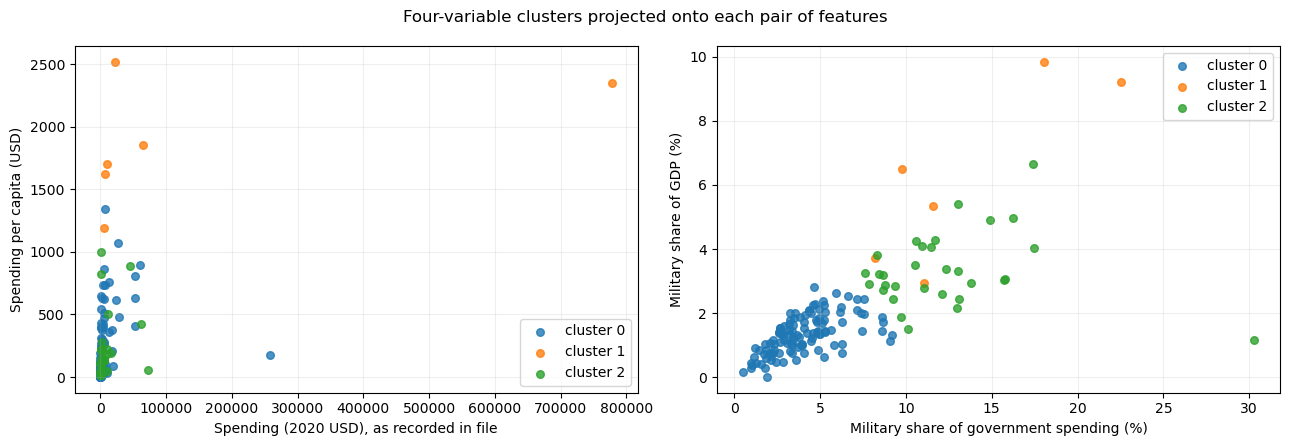

Part 2 vs. all four:
cluster_all        0  1   2
cluster_spending           
0                 85  0  26
1                 25  0   5
2                  0  1   0
3                  1  5   0
Part 3 vs. all four:
cluster_all      0  1   2
cluster_shares           
0               12  2  25
1               99  0   0
2                0  4   6
                 Country  cluster_spending  cluster_shares  cluster_all
United States of America                 2               0            1


In [52]:
sse_all = []

for k in k_grid:
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X_scaled[features])
    sse_all.append(model.inertia_)

print(pd.DataFrame({
    'k': list(k_grid), 'SSE': sse_all
}).round(4))

plt.figure(figsize=(8, 4))
plt.plot(list(k_grid), sse_all, marker='o')
plt.axvline(3, linestyle='--', color='gray', label='chosen k = 3')
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('All four normalized variables: scree plot')
plt.xticks(list(k_grid))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

k_all = 3
all_model = KMeans(
    n_clusters=k_all, random_state=100, n_init=20
)
df2020['cluster_all'] = all_model.fit_predict(X_scaled[features])

display(
    df2020.groupby('cluster_all')[features].describe().round(4)
)

means_all = df2020.groupby('cluster_all')[features].mean()
means_all[share_features] = 100 * means_all[share_features]

print('Cluster means (share columns shown in percent):')
print(means_all.round(2))
print('Cluster sizes:')
print(df2020['cluster_all'].value_counts().sort_index())

print('Countries in the high-per-capita cluster:')
print(
    ', '.join(
        df2020.loc[df2020['cluster_all'] == 1, 'Country']
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for cluster in sorted(df2020['cluster_all'].unique()):
    sub = df2020[df2020['cluster_all'] == cluster]
    axes[0].scatter(
        sub[features[0]], sub[features[1]],
        s=30, alpha=0.8, label=f'cluster {cluster}'
    )
    axes[1].scatter(
        100 * sub[features[2]], 100 * sub[features[3]],
        s=30, alpha=0.8, label=f'cluster {cluster}'
    )

axes[0].set_xlabel('Spending (2020 USD), as recorded in file')
axes[0].set_ylabel('Spending per capita (USD)')
axes[1].set_xlabel('Military share of government spending (%)')
axes[1].set_ylabel('Military share of GDP (%)')

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle('Four-variable clusters projected onto each pair of features')
plt.tight_layout()
plt.show()

print('Part 2 vs. all four:')
print(pd.crosstab(df2020['cluster_spending'], df2020['cluster_all']))

print('Part 3 vs. all four:')
print(pd.crosstab(df2020['cluster_shares'], df2020['cluster_all']))

print(
    df2020.loc[
        df2020['Country'] == 'United States of America',
        ['Country', 'cluster_spending', 'cluster_shares', 'cluster_all']
    ].to_string(index=False)
)

I choose $k=3$. SSE falls from 12.3724 to 7.7096 to 5.1926, followed by a smaller reduction to 4.2070 at $k=4$. The elbow is broad, so 4 or 5 would provide a more detailed partition. Three gives a useful summary without assuming every subdivision represents a separate kind of country. Absolute SSE values should be compared within each feature set because the four-variable fit contains more distance components than the two-variable fits.

The four-variable result combines the earlier patterns. Cluster 0 contains 111 countries averaging 4.04% of government spending and 1.34% of GDP on the military, with mean per-capita spending of $196.93. Cluster 2 contains 31 countries with higher mean shares of 12.30% and 3.35%, but similar mean per-capita spending of $212.69. This distinction is mainly about resource allocation rather than dollars per person.

Cluster 1 contains Israel, Kuwait, Oman, Saudi Arabia, Singapore, and the U.S. They average $1,875.15 per person, 13.54% of government spending, and 6.26% of GDP. The U.S. is no longer a singleton. Norway, which belonged to the high-per-capita cluster in part 2, now belongs to cluster 0 because of its lower military shares.

The crosstabs show how these partitions relate without assuming that their numeric labels match. All 99 countries from the low-share cluster in part 3 belong to cluster 0 here. The six-country cluster combines the U.S. with five members of the high-per-capita cluster from part 2.

The scatterplots are two-dimensional projections of a four-dimensional fit. Countries that overlap in one panel can differ on the other features. Also, changing from four clusters in part 2 to three here contributes to the broader grouping, so the differences cannot be attributed only to adding features.

### Q2.5 - Were the patterns useful?

Yes. The most useful distinction is between the size of a military budget, spending per person, and the share of a country's resources allocated to the military. The U.S. stands out in total spending. Norway stands out more by spending per person than by military budget shares. Algeria and Pakistan belong to the high-share group without belonging to the high-per-capita group. Combining all four variables brings these different views together.

I would use the clusters as summaries and starting points for comparisons rather than fixed country classifications. Feature selection, scaling, and the choice of $k$ affect the result. Min-max scaling prevents the original dollar units from dominating, but it does not remove skewness or outlier influence. The U.S. maximum compresses most other normalized total budgets near zero. The two share variables are also related, so equal feature ranges do not represent independent pieces of information.

The sensitivity analysis strengthens the interpretation by showing which memberships persist when the flagged observations are excluded and scaling is refitted. The spending-only memberships remain unchanged among retained countries, and the high-share and high-per-capita groups largely persist, although some other assignments shift.

Finally, $k$-means divides even overlapping data into clusters, as Q1 demonstrates. The broad elbows mean the boundaries should not be overinterpreted. These results describe one year's spending among countries with complete data; they do not establish why countries spend differently or measure military capability.

### *Reflection on AI assistance


For this assignment, I found the AI-assisted revisions to be useful in improving my original analysis, specifically by expanding upon some of the results and providing additional ways of interpreting them. For Question 1, adding the Adjusted Rand Index and misassignment counts allowed me to better understand how increasing noise affected the accuracy of K-means clustering. Similarly, for Question 2, examining the unusual observations in the military expenditure data helped highlight how individual countries could influence the resulting clusters.

However, I found that not all of the AI's suggestions were appropriate. One example was its claim that my reported 32% reduction in SSE was incorrect, even though the actual reduction was approximately 31.82%. Furthermore, I disagreed with replacing the original analysis by excluding certain observations, as I felt this would change the results without sufficiently justifying why those countries should be removed. Instead, I chose to keep the original analysis and examine the exclusions separately.

To verify the changes, I recalculated the reported values using the original dataset and compared the clustering results before and after the proposed revisions. This was particularly useful in identifying which suggestions provided meaningful improvements rather than simply adding unnecessary complexity.

One concern I still have is how sensitive K-means can be to outliers and the choice of variables. Even removing a few observations can influence the resulting clusters. Overall, I found the AI revisions valuable, but this assignment also highlighted the importance of independently evaluating its suggestions rather than accepting them at face value.